In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import classification_report
from sklearn.feature_selection import SelectKBest, chi2

from xgboost import XGBClassifier

import csv

import joblib

from tensorflow.keras.models import load_model

In [2]:
data=pd.read_csv("dataset_phishing.csv",sep=",")

In [3]:
data

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,0,0,0,448,5396,3980,0,0,6,legitimate
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,0,...,1,0,0,211,6728,0,0,1,0,phishing
11427,https://www.facebook.com/Interactive-Televisio...,105,16,1,2,6,0,1,0,0,...,0,0,0,2809,8515,8,0,1,10,legitimate
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,1,0,0,85,2836,2455493,0,0,4,legitimate


In [4]:
data_mejorada = data.copy()

In [5]:
data_mejorada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,0,0,0,448,5396,3980,0,0,6,legitimate
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,0,...,1,0,0,211,6728,0,0,1,0,phishing
11427,https://www.facebook.com/Interactive-Televisio...,105,16,1,2,6,0,1,0,0,...,0,0,0,2809,8515,8,0,1,10,legitimate
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,1,0,0,85,2836,2455493,0,0,4,legitimate


In [7]:
# Invertir los valores de la columna 'ip': 0 a 1 y 1 a 0
data_mejorada['google_index'] = data['google_index'].apply(lambda x: 1 if x == 0 else 0)

# Invertir los valores de la columna 'domain_with_copyright': 0 a 1 y 1 a 0
data_mejorada['domain_with_copyright'] = data['domain_with_copyright'].apply(lambda x: 1 if x == 0 else 0)

# Invertir los valores de la columna 'https_token': 0 a 1 y 1 a 0
data_mejorada['https_token'] = data['https_token'].apply(lambda x: 1 if x == 0 else 0)

# Invertir los valores de la columna 'whois_registered_domain': 0 a 1 y 1 a 0
data_mejorada['whois_registered_domain'] = data['whois_registered_domain'].apply(lambda x: 1 if x == 0 else 0)

# Invertir los valores de la columna 'domain_in_title': 0 a 1 y 1 a 0
data_mejorada['domain_in_title'] = data['domain_in_title'].apply(lambda x: 1 if x == 0 else 0)

# Invertir los valores de la columna 'dns_record': 0 a 1 y 1 a 0
data_mejorada['dns_record'] = data['dns_record'].apply(lambda x: 1 if x == 0 else 0)

In [8]:
data_mejorada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,0,1,1,14,4004,5828815,1,0,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,legitimate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,legitimate
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,0,...,0,1,1,211,6728,0,1,0,0,phishing
11427,https://www.facebook.com/Interactive-Televisio...,105,16,1,2,6,0,1,0,0,...,1,1,1,2809,8515,8,1,0,10,legitimate
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,legitimate


In [9]:
import pandas as pd
import re
from urllib.parse import urlparse

# Función para verificar si un dominio contiene una dirección IP
def having_ip_address(url):
    match = re.search(
        r'(([01]?\d\d?|2[0-4]\d|25[0-5])\.([01]?\d\d?|2[0-4]\d|25[0-5])\.([01]?\d\d?|2[0-4]\d|25[0-5]))|'  # IPv4
        r'((0x[0-9a-fA-F]{1,2})\.(0x[0-9a-fA-F]{1,2})\.(0x[0-9a-fA-F]{1,2})\.(0x[0-9a-fA-F]{1,2}))|'  # IPv4 hex
        r'(?:[a-fA-F0-9]{1,4}:){7}[a-fA-F0-9]{1,4}',  # IPv6
        url
    )
    return 1 if match else 0

# Analizar la columna "url" y extraer el dominio, luego verificar si contiene una IP
data_mejorada['ip'] = data_mejorada['url'].apply(lambda x: having_ip_address(urlparse(x).netloc))

In [13]:
data_mejorada[data_mejorada['ip'] == 1].sample(n=90)

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
3047,http://139.59.201.27/banks/National/98e8eacead...,69,13,1,3,0,0,0,0,0,...,0,1,0,0,-1,0,0,0,0,1
8171,http://98.126.214.77/ap/signin?key=a@b.c&amp;o...,425,13,1,24,0,1,2,8,0,...,0,0,0,0,-1,0,0,0,0,1
11208,http://216.222.194.94/images/social/sign-in/,44,14,1,3,1,0,0,0,0,...,0,1,0,0,-1,0,0,0,0,1
6402,http://45.238.23.82/user-login.php,34,12,1,4,1,0,0,0,0,...,0,1,0,0,-1,0,0,0,0,1
9264,http://124.156.218.50/ap/signin?key=a@b.c,41,14,1,4,0,1,1,0,0,...,0,0,0,0,-1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6351,http://174.139.46.28/ap/signin?key=a@b.c,40,13,1,4,0,1,1,0,0,...,0,1,0,0,-1,0,0,0,0,1
385,http://67.199.68.195/intservices.htm,36,13,1,4,0,0,0,0,0,...,0,1,0,0,-1,0,0,1,0,1
10289,http://68.66.220.82/administrator/help/en-GB/a...,82,12,1,5,1,1,1,0,0,...,0,1,0,0,-1,0,0,0,0,1
3325,http://201.163.98.162/crm/jssource/src_files/m...,91,14,1,3,0,0,0,0,0,...,0,1,0,0,-1,0,0,0,0,1


In [11]:
data_mejorada['status'] = data_mejorada['status'].apply(lambda x: 1 if x == 'phishing' else 0)

In [12]:
data_mejorada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,0
1,http://shadetreetechnology.com/V4/validation/a...,77,23,0,1,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,1
2,https://support-appleld.com.secureupdate.duila...,126,50,0,4,1,0,1,2,0,...,0,1,1,14,4004,5828815,1,0,0,1
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,0
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,0
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,0,...,0,1,1,211,6728,0,1,0,0,1
11427,https://www.facebook.com/Interactive-Televisio...,105,16,0,2,6,0,1,0,0,...,1,1,1,2809,8515,8,1,0,10,0
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,0


In [ ]:
####################################################################################################################################################################################################################################################################################################################################################
################################################################################################################################################################################################################################################
################################################################################################################################################################################################################################################
################################################################################################################################################################################################################################################

In [14]:
data_mejorada["status"].value_counts()

status
0    5715
1    5715
Name: count, dtype: int64

Completitud del Dataset:
                 Valores Nulos  Porcentaje de Nulos (%)
url                          0                      0.0
length_url                   0                      0.0
length_hostname              0                      0.0
ip                           0                      0.0
nb_dots                      0                      0.0
...                        ...                      ...
web_traffic                  0                      0.0
dns_record                   0                      0.0
google_index                 0                      0.0
page_rank                    0                      0.0
status                       0                      0.0

[89 rows x 2 columns]


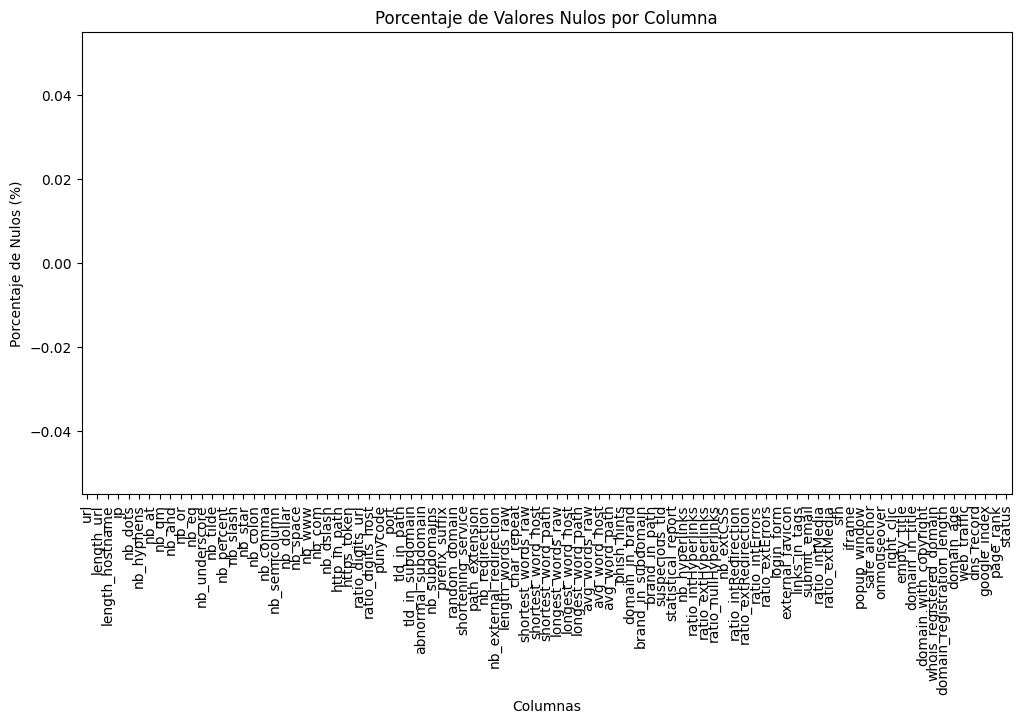

In [15]:
### Análisis de Completitud ###

# Verificar y contar valores nulos en cada columna
valores_nulos = data_mejorada.isnull().sum()
porcentaje_nulos = (valores_nulos / len(data_mejorada)) * 100

# Crear un DataFrame con el conteo y porcentaje de valores nulos
nulos_df = pd.DataFrame({
    'Valores Nulos': valores_nulos,
    'Porcentaje de Nulos (%)': porcentaje_nulos
})

# Mostrar el DataFrame de valores nulos
print("Completitud del Dataset:")
print(nulos_df)

# Graficar el porcentaje de valores nulos por columna con una paleta de colores
plt.figure(figsize=(12, 6))
sns.barplot(
    x=nulos_df.index, 
    y=nulos_df['Porcentaje de Nulos (%)'], 
    color="skyblue"  # Usar un color fijo
)
plt.xticks(rotation=90)
plt.title("Porcentaje de Valores Nulos por Columna")
plt.xlabel("Columnas")
plt.ylabel("Porcentaje de Nulos (%)")
plt.show()

Estadísticas Descriptivas:
         length_url  length_hostname            ip       nb_dots  \
count  11430.000000     11430.000000  11430.000000  11430.000000   
mean      61.126684        21.090289      0.008661      2.480752   
std       55.297318        10.777171      0.092667      1.369686   
min       12.000000         4.000000      0.000000      1.000000   
25%       33.000000        15.000000      0.000000      2.000000   
50%       47.000000        19.000000      0.000000      2.000000   
75%       71.000000        24.000000      0.000000      3.000000   
max     1641.000000       214.000000      1.000000     24.000000   

         nb_hyphens         nb_at         nb_qm        nb_and    nb_or  \
count  11430.000000  11430.000000  11430.000000  11430.000000  11430.0   
mean       0.997550      0.022222      0.141207      0.162292      0.0   
std        2.087087      0.155500      0.364456      0.821337      0.0   
min        0.000000      0.000000      0.000000      0.000000   

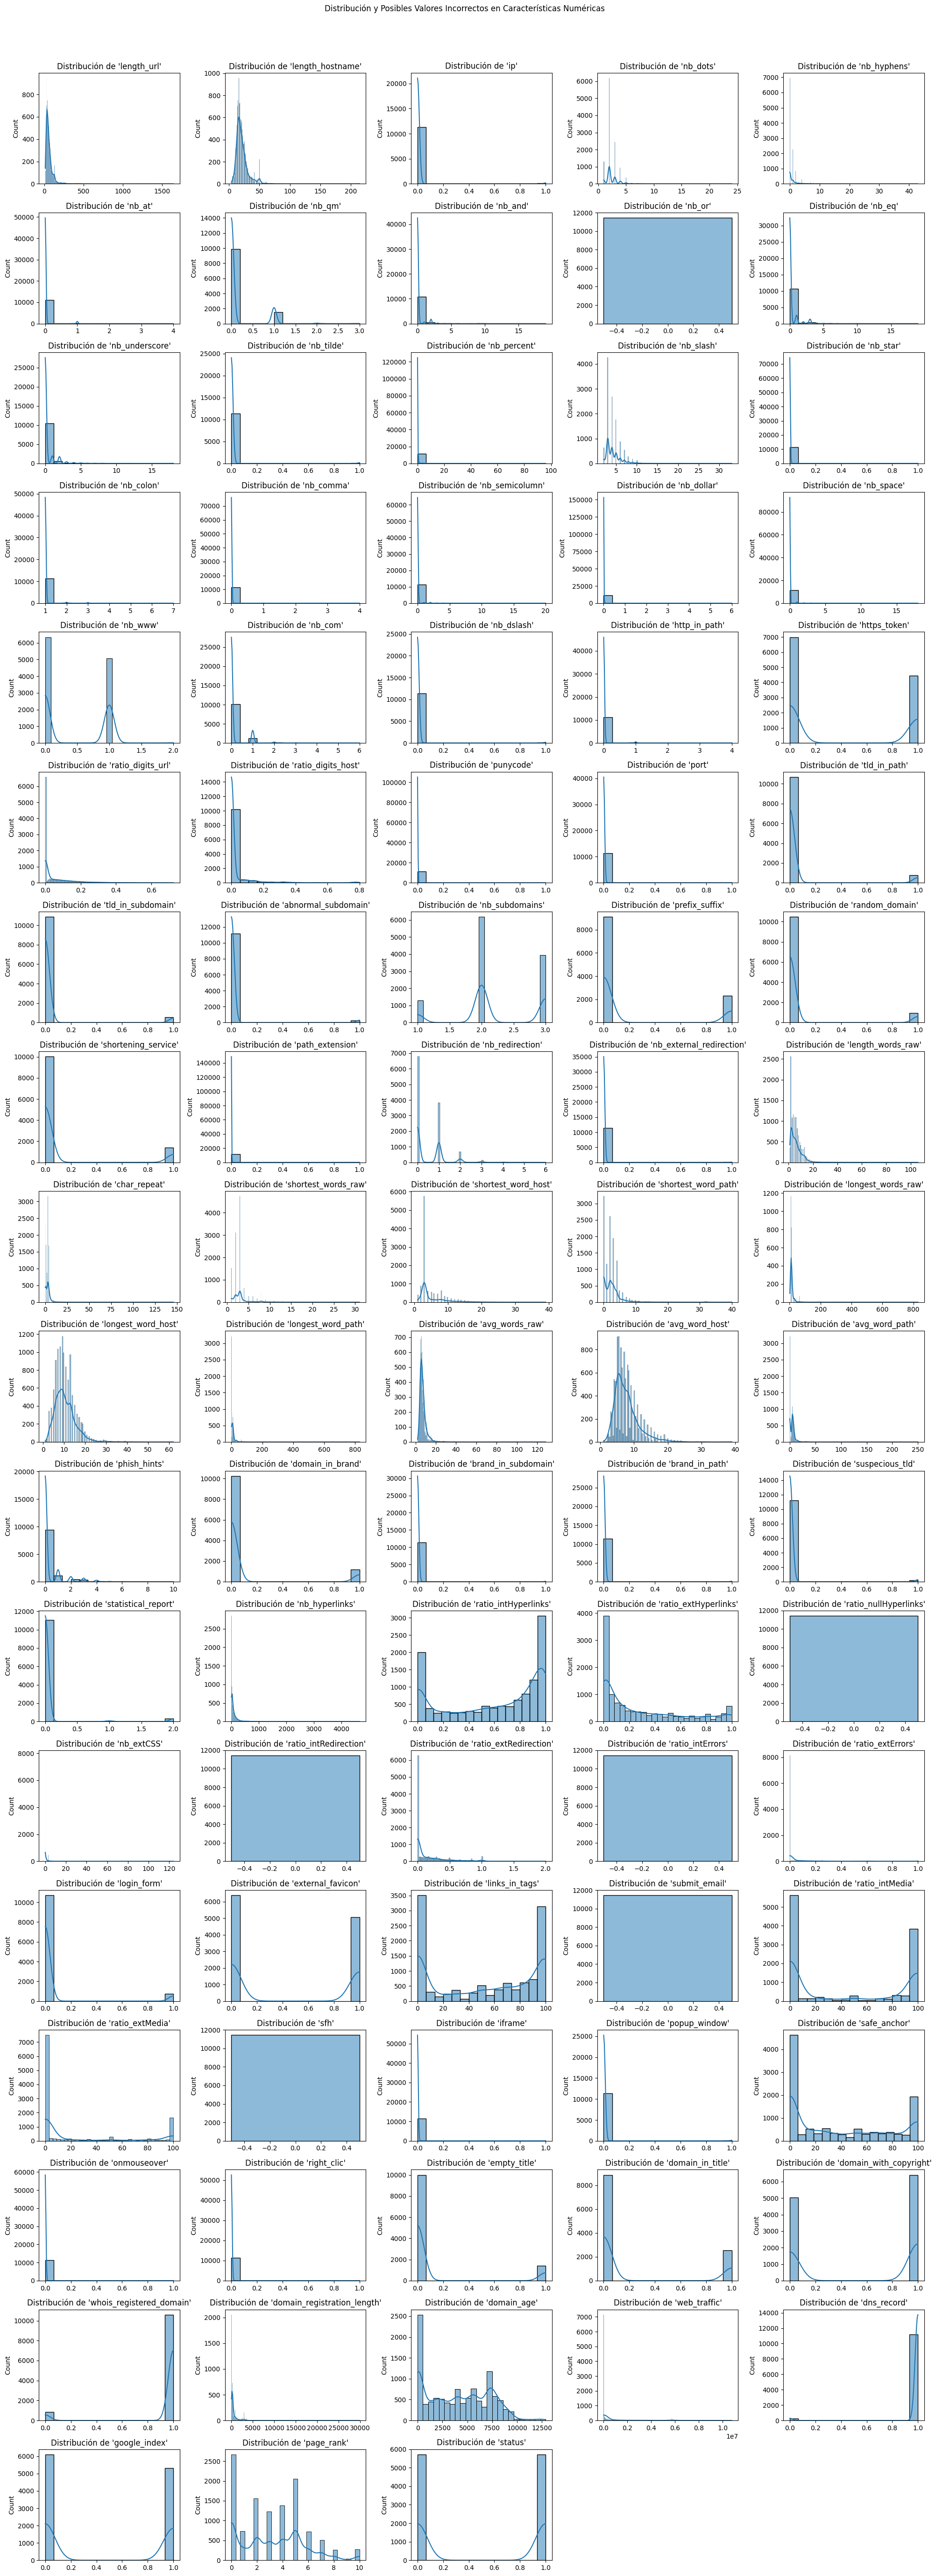

In [16]:
### Análisis de Correctitud ###

# Describir el dataset para obtener estadísticas básicas (media, mediana, min, max, etc.)
print("Estadísticas Descriptivas:")
print(data_mejorada.describe())

# Detectar valores inusuales (ejemplo: valores negativos donde no deberían estar)
valores_incorrectos = {}
for col in data_mejorada.columns:
    if data_mejorada[col].dtype in ['float64', 'int64']:  # Solo columnas numéricas
        # Identificar valores negativos (ejemplo de valor incorrecto)
        incorrect_values = data_mejorada[data_mejorada[col] < 0]
        if not incorrect_values.empty:
            valores_incorrectos[col] = incorrect_values[col].values
            print(f"\nValores incorrectos en '{col}':")
            print(incorrect_values[col])

# Crear gráficos de distribución para cada columna numérica
num_cols = data_mejorada.select_dtypes(include=['float64', 'int64']).columns
num_plots = len(num_cols)
cols = 5  # Número de columnas de subplots
rows = math.ceil(num_plots / cols)  # Número de filas necesarias

plt.figure(figsize=(cols * 4, rows * 3))
for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(data_mejorada[col], kde=True)
    plt.title(f"Distribución de '{col}'")
    plt.xlabel("")
plt.tight_layout()
plt.suptitle("Distribución y Posibles Valores Incorrectos en Características Numéricas", y=1.02)
plt.show()

In [19]:
# Verificar valores únicos en la columna 'X'
print("Valores únicos en 'X':", data['sfh'].unique())

# Contar valores únicos y verificar si hay valores nulos
print("Conteo de valores en 'X':")
print(data['sfh'].value_counts(dropna=False))

# Revisar si hay nulos en 'X'
print("Cantidad de valores nulos en 'X':", data['sfh'].isnull().sum())

Valores únicos en 'X': [0]
Conteo de valores en 'X':
sfh
0    11430
Name: count, dtype: int64
Cantidad de valores nulos en 'X': 0


In [22]:
data_mejorada.shape

(11430, 89)

In [23]:
data_filtrada = data_mejorada.loc[:, data_mejorada.nunique() > 1].copy()

In [24]:
data_filtrada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,0
1,http://shadetreetechnology.com/V4/validation/a...,77,23,0,1,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,1
2,https://support-appleld.com.secureupdate.duila...,126,50,0,4,1,0,1,2,3,...,0,1,1,14,4004,5828815,1,0,0,1
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,0
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,0
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,1,...,0,1,1,211,6728,0,1,0,0,1
11427,https://www.facebook.com/Interactive-Televisio...,105,16,0,2,6,0,1,0,1,...,1,1,1,2809,8515,8,1,0,10,0
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,0


In [25]:
data_filtrada.shape

(11430, 83)

length_url: 620 outliers
length_hostname: 775 outliers
ip: 99 outliers
nb_dots: 567 outliers
nb_hyphens: 1371 outliers
nb_at: 245 outliers
nb_qm: 1555 outliers
nb_and: 761 outliers
nb_or: 0 outliers
nb_eq: 1564 outliers
nb_underscore: 1695 outliers
nb_tilde: 76 outliers
nb_percent: 355 outliers
nb_slash: 401 outliers
nb_star: 8 outliers
nb_colon: 197 outliers
nb_comma: 24 outliers
nb_semicolumn: 248 outliers
nb_dollar: 11 outliers
nb_space: 210 outliers
nb_www: 0 outliers
nb_com: 1327 outliers
nb_dslash: 75 outliers
http_in_path: 150 outliers
https_token: 0 outliers
ratio_digits_url: 933 outliers
ratio_digits_host: 1503 outliers
punycode: 4 outliers
port: 27 outliers
tld_in_path: 750 outliers
tld_in_subdomain: 573 outliers
abnormal_subdomain: 247 outliers
nb_subdomains: 0 outliers
prefix_suffix: 2314 outliers
random_domain: 952 outliers
shortening_service: 1411 outliers
path_extension: 2 outliers
nb_redirection: 166 outliers
nb_external_redirection: 36 outliers
length_words_raw: 264 ou

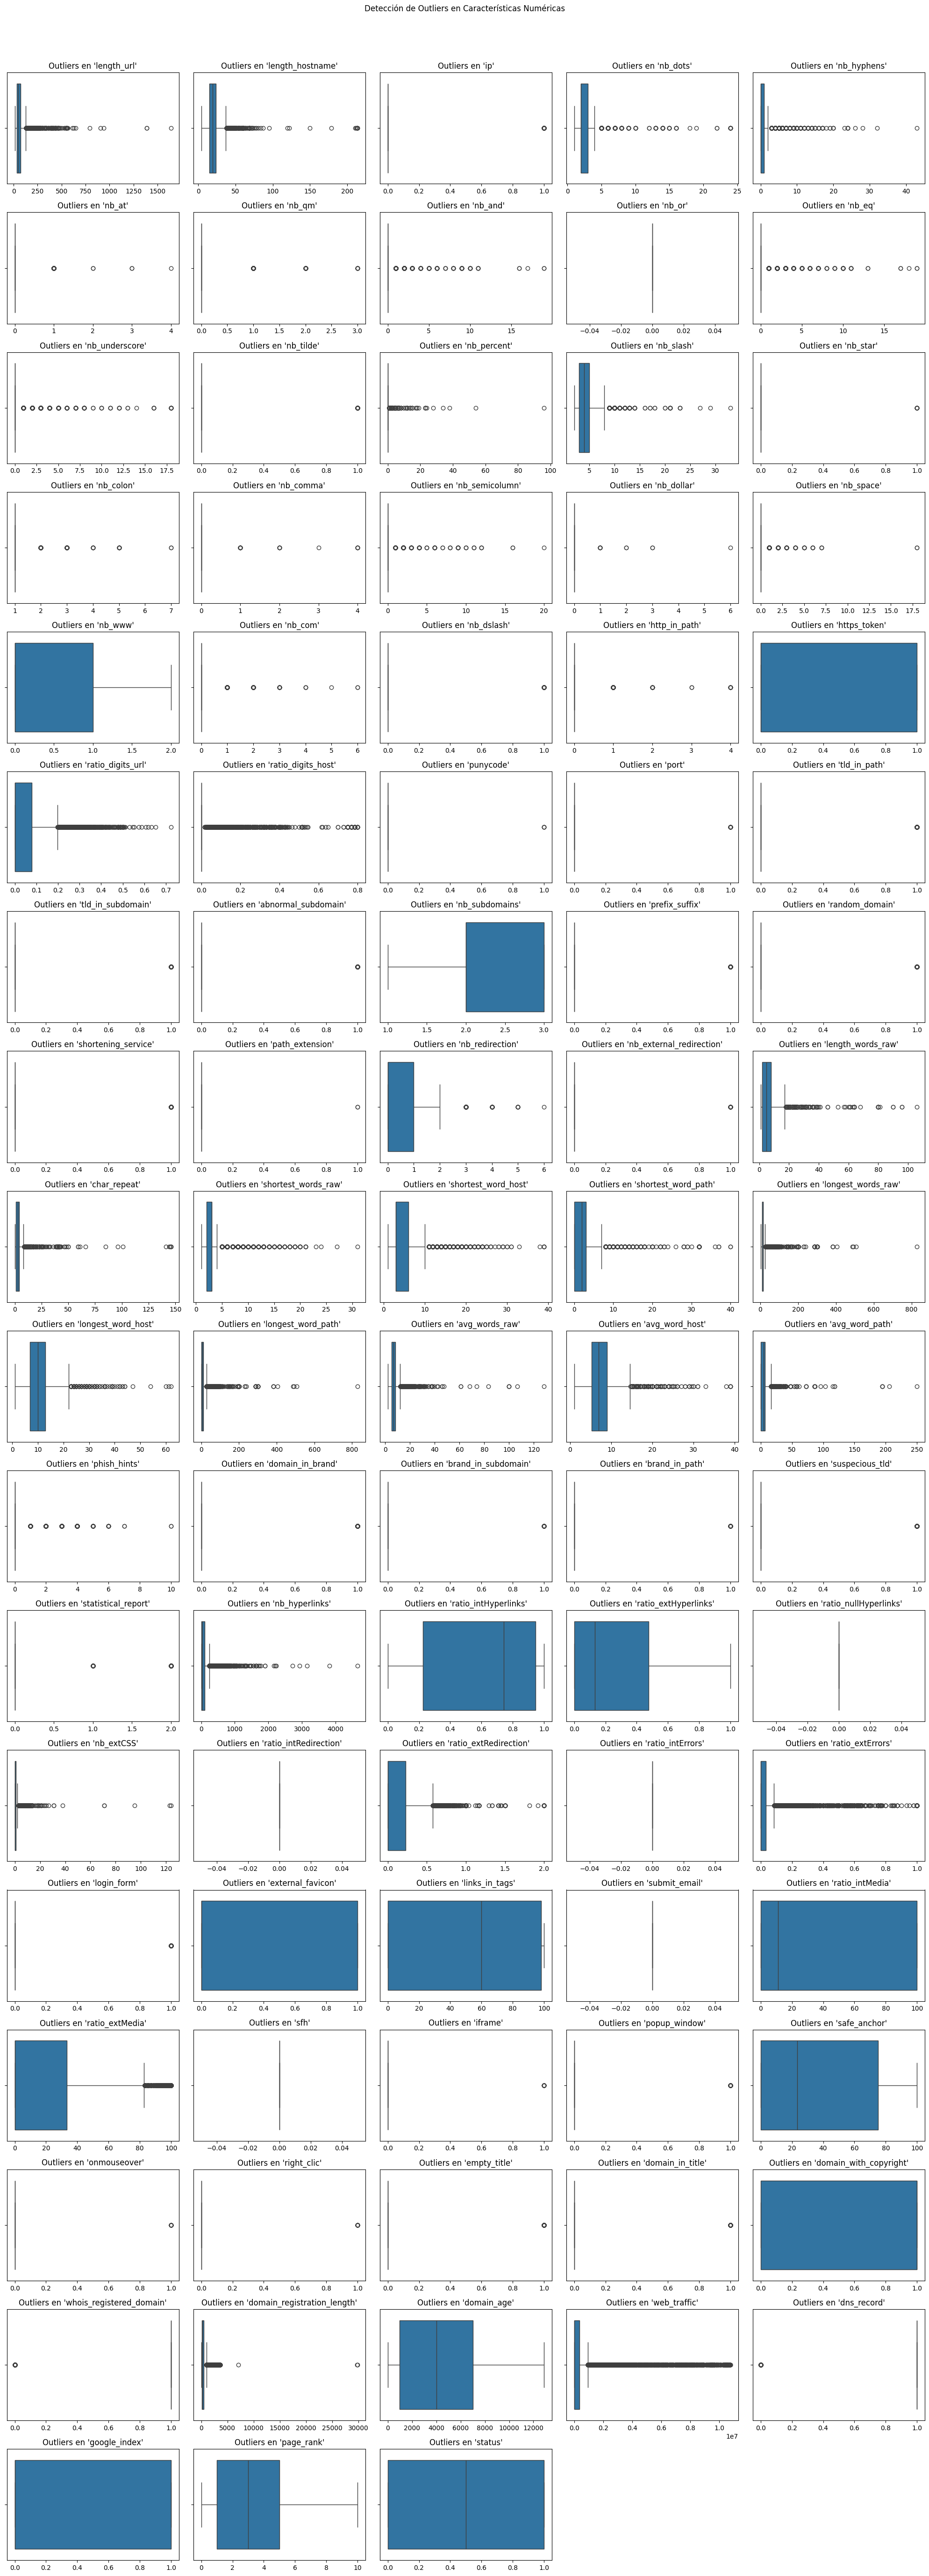

In [26]:
### Detección de Outliers ###

# Función para detectar outliers usando el método de Rango Intercuartílico (IQR)
def detectar_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Detección y conteo de outliers para cada columna numérica
outliers_info = {}
for col in data_mejorada.select_dtypes(include=['float64', 'int64']).columns:
    outliers = detectar_outliers(data_mejorada, col)
    outliers_info[col] = len(outliers)
    print(f"{col}: {len(outliers)} outliers")

# Convertir el diccionario en un DataFrame para mejor visualización
outliers_df = pd.DataFrame(list(outliers_info.items()), columns=['Columna', 'Cantidad de Outliers'])
print("\nResumen de Outliers por Columna:")
print(outliers_df)

# Visualización de Outliers usando Boxplots
num_cols = data_mejorada.select_dtypes(include=['float64', 'int64']).columns
num_plots = len(num_cols)
cols = 5  # Número de columnas de subplots
rows = math.ceil(num_plots / cols)  # Número de filas necesarias

plt.figure(figsize=(cols * 4, rows * 3))
for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=data_mejorada[col])
    plt.title(f"Outliers en '{col}'")
    plt.xlabel("")
plt.tight_layout()
plt.suptitle("Detección de Outliers en Características Numéricas", y=1.02)
plt.show()


In [27]:
data_mejorada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,0
1,http://shadetreetechnology.com/V4/validation/a...,77,23,0,1,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,1
2,https://support-appleld.com.secureupdate.duila...,126,50,0,4,1,0,1,2,0,...,0,1,1,14,4004,5828815,1,0,0,1
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,0
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,0
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,0,...,0,1,1,211,6728,0,1,0,0,1
11427,https://www.facebook.com/Interactive-Televisio...,105,16,0,2,6,0,1,0,0,...,1,1,1,2809,8515,8,1,0,10,0
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,0


In [28]:
data_filtrada

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,0
1,http://shadetreetechnology.com/V4/validation/a...,77,23,0,1,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,1
2,https://support-appleld.com.secureupdate.duila...,126,50,0,4,1,0,1,2,3,...,0,1,1,14,4004,5828815,1,0,0,1
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,0
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,45,17,0,2,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,0
11426,http://www.budgetbots.com/server.php/Server%20...,84,18,0,5,0,1,1,0,1,...,0,1,1,211,6728,0,1,0,0,1
11427,https://www.facebook.com/Interactive-Televisio...,105,16,0,2,6,0,1,0,1,...,1,1,1,2809,8515,8,1,0,10,0
11428,http://www.mypublicdomainpictures.com/,38,30,0,2,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,0


In [29]:
data_filtrada = data_filtrada.drop(columns=["url"])

In [30]:
data_filtrada

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,37,19,0,3,0,0,0,0,0,0,...,1,0,1,45,-1,0,0,0,4,0
1,77,23,0,1,0,0,0,0,0,0,...,0,1,1,77,5767,0,1,0,2,1
2,126,50,0,4,1,0,1,2,3,2,...,0,1,1,14,4004,5828815,1,0,0,1
3,18,11,0,2,0,0,0,0,0,0,...,0,1,1,62,-1,107721,1,1,3,0
4,55,15,0,2,2,0,0,0,0,0,...,1,0,1,224,8175,8725,1,1,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,45,17,0,2,0,0,0,0,0,0,...,1,1,1,448,5396,3980,1,1,6,0
11426,84,18,0,5,0,1,1,0,1,0,...,0,1,1,211,6728,0,1,0,0,1
11427,105,16,0,2,6,0,1,0,1,1,...,1,1,1,2809,8515,8,1,0,10,0
11428,38,30,0,2,0,0,0,0,0,0,...,0,1,1,85,2836,2455493,1,1,4,0


In [31]:
# 1. Gráfico de correlación de cada característica con la variable objetivo 'estado'
correlaciones = data_filtrada.corr()['status'].abs().sort_values(ascending=False)
print("Correlación de características con la variable objetivo 'estado':")
print(correlaciones)

Correlación de características con la variable objetivo 'estado':
status              1.000000e+00
google_index        7.311708e-01
page_rank           5.111371e-01
nb_www              4.434677e-01
ratio_digits_url    3.563946e-01
                        ...     
port                9.011116e-03
onmouseover         7.787061e-03
right_clic          4.680056e-03
nb_space            4.193222e-03
path_extension      5.592660e-17
Name: status, Length: 82, dtype: float64


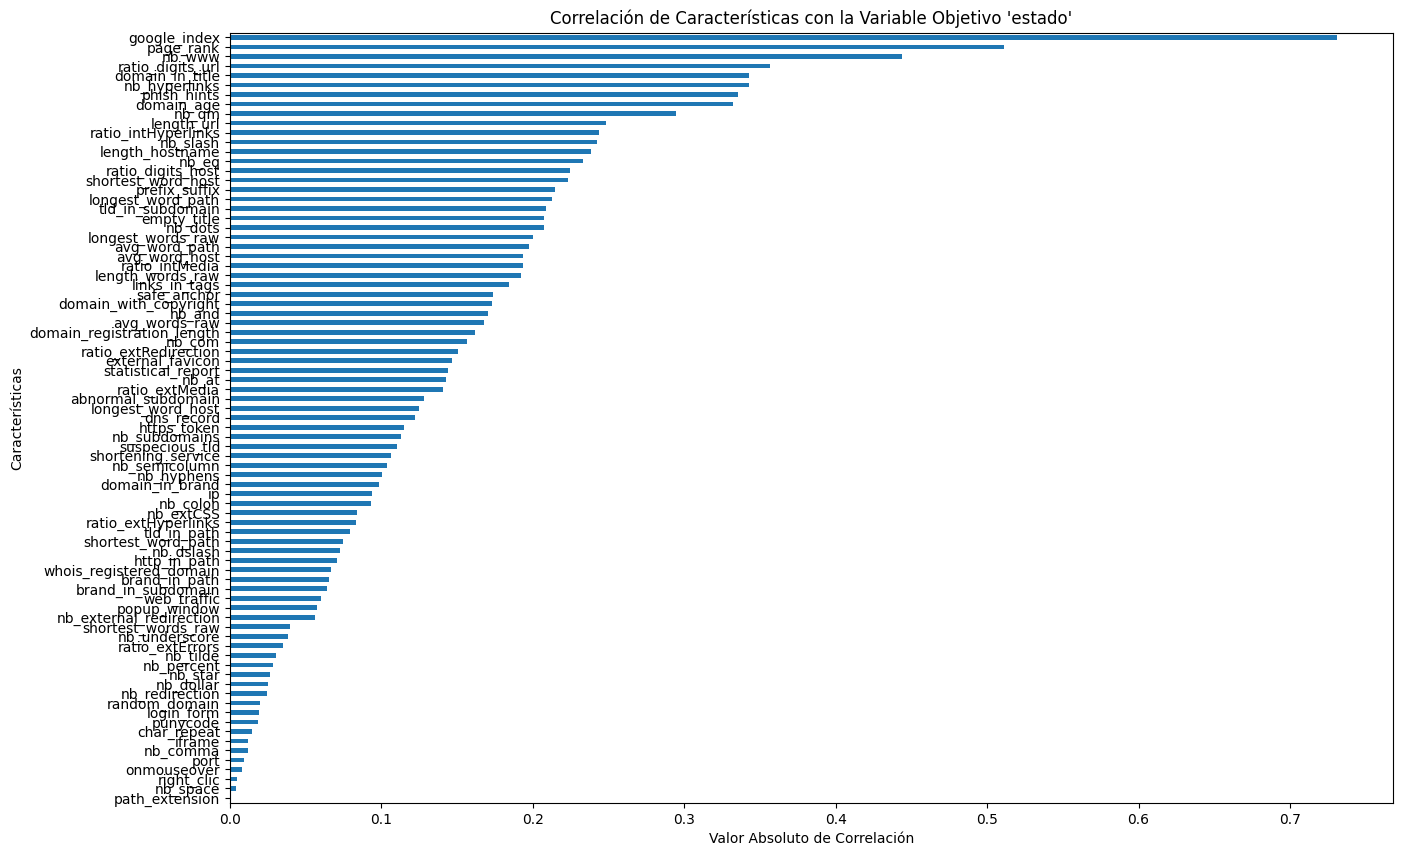

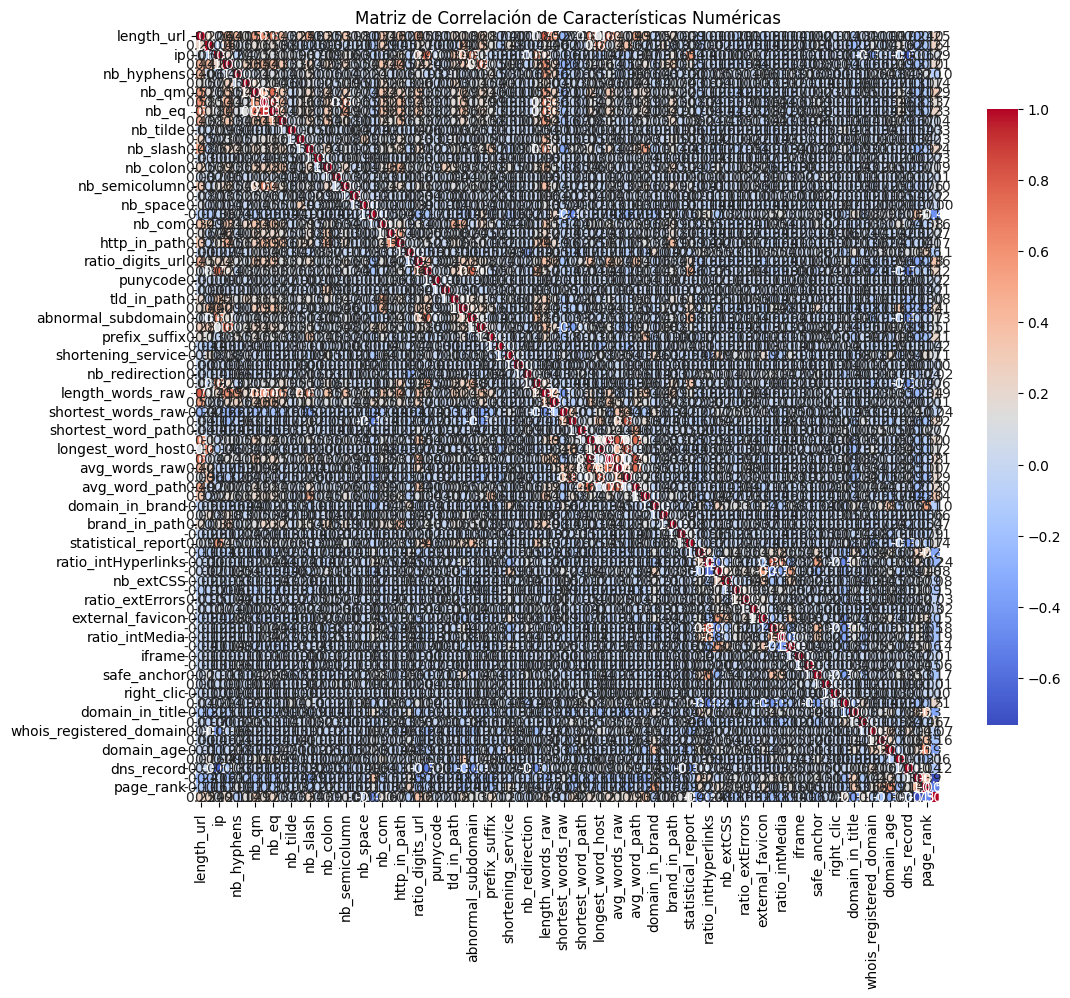

In [32]:
# Gráfico de barras horizontal para visualizar la correlación con 'estado'
plt.figure(figsize=(15, 10))
correlaciones[1:].plot(kind='barh')  # Excluir 'estado' de sí mismo
plt.title("Correlación de Características con la Variable Objetivo 'estado'")
plt.xlabel("Valor Absoluto de Correlación")
plt.ylabel("Características")
plt.gca().invert_yaxis()  # Invertir el eje Y para que las características con mayor correlación estén arriba
plt.show()

# 2. Matriz de correlación de todas las características numéricas
plt.figure(figsize=(12, 10))
sns.heatmap(data_filtrada.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'shrink': .8})
plt.title("Matriz de Correlación de Características Numéricas")
plt.show()


<Axes: xlabel='status'>

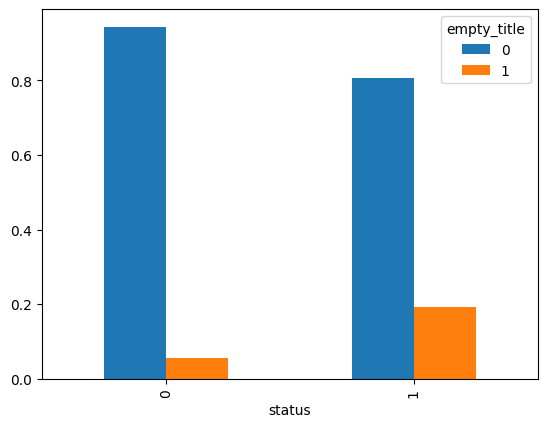

In [43]:
pd.crosstab(data_mejorada["status"],data_mejorada["empty_title"],normalize="index").plot.bar()

In [33]:
def detectar_columnas_negativas(df):
    
    columnas_negativas = df.columns[(df < 0).any()].tolist()
    return columnas_negativas

# Ejemplo de uso
columnas_con_negativos = detectar_columnas_negativas(data_filtrada)
print("Columnas con valores negativos:", columnas_con_negativos)

Columnas con valores negativos: ['domain_registration_length', 'domain_age']


In [35]:
# Separar características (X) y variable objetivo (y)
X = data_filtrada.drop(columns=["status"])
y = data_filtrada['status']

In [36]:
# Contar el número de instancias en cada clase
print("Distribución de la variable objetivo:")
print(y.value_counts())

# Calcular el porcentaje de cada clase
print("\nPorcentaje de cada clase:")
print(y.value_counts(normalize=True) * 100)

Distribución de la variable objetivo:
status
0    5715
1    5715
Name: count, dtype: int64

Porcentaje de cada clase:
status
0    50.0
1    50.0
Name: proportion, dtype: float64


In [37]:
# Entrenar un modelo de XGBoost
model_XGB = XGBClassifier(random_state=42, eval_metric='logloss')  # Quitar use_label_encoder
model_XGB.fit(X, y)

# Obtener las importancias de las características
importancias_XGB = model_XGB.feature_importances_

# Crear un DataFrame para ordenar las importancias
importancias_df_XGB = pd.DataFrame({
    'Característica': X.columns,
    'Importancia': importancias_XGB
}).sort_values(by='Importancia', ascending=False)

xgb_k = 46  # Número de características más importantes a mostrar
print(f"Las {xgb_k} características más importantes según XGBoost:")
print(importancias_df_XGB.head(xgb_k))

# Seleccionar las mejores características según XGBoost
mejores_columnas_XGB = importancias_df_XGB.head(xgb_k)['Característica'].values


Las 46 características más importantes según XGBoost:
             Característica  Importancia
79             google_index     0.510116
6                     nb_qm     0.041375
80                page_rank     0.039480
19                   nb_www     0.036677
25        ratio_digits_host     0.029401
55            nb_hyperlinks     0.027688
49              phish_hints     0.023452
53           suspecious_tld     0.014467
45        longest_word_path     0.012574
50          domain_in_brand     0.012490
38         length_words_raw     0.011575
11               nb_percent     0.011550
4                nb_hyphens     0.011275
77              web_traffic     0.010700
9             nb_underscore     0.010300
71              empty_title     0.009338
68              safe_anchor     0.008922
12                 nb_slash     0.007849
72          domain_in_title     0.007762
3                   nb_dots     0.007738
8                     nb_eq     0.007312
42       shortest_word_path     0.007282
1  

In [38]:
# Entrenar un Random Forest para calcular importancia
model_RF = RandomForestClassifier(random_state=42)
model_RF.fit(X, y)

# Obtener las importancias de las características
importancias_RF = model_RF.feature_importances_

# Crear un DataFrame para mostrar la importancia de cada característica
importancias_df_RF = pd.DataFrame({
    'Característica': X.columns,
    'Importancia': importancias_RF
}).sort_values(by='Importancia', ascending=False)

rf_k = 46

# Mostrar las características más importantes
print(f"Las {rf_k} características más importantes:")
print(importancias_df_RF.head(rf_k))

# Seleccionar las mejores características según Random Forest
mejores_columnas_RF = importancias_df_RF.head(rf_k)['Característica'].values

Las 46 características más importantes:
                Característica  Importancia
79                google_index     0.188028
80                   page_rank     0.107835
55               nb_hyperlinks     0.093172
77                 web_traffic     0.086452
19                      nb_www     0.038048
76                  domain_age     0.031767
57         ratio_extHyperlinks     0.028660
45           longest_word_path     0.027039
49                 phish_hints     0.025148
68                 safe_anchor     0.022171
56         ratio_intHyperlinks     0.021085
24            ratio_digits_url     0.019006
0                   length_url     0.018215
1              length_hostname     0.017654
43           longest_words_raw     0.014987
72             domain_in_title     0.014874
38            length_words_raw     0.014613
48               avg_word_path     0.013778
25           ratio_digits_host     0.013401
59        ratio_extRedirection     0.012935
39                 char_repeat     0

In [39]:
# Asegurarse de que todas las características sean no negativas para chi2
X_copy = X.clip(lower=0)  # Chi2 requiere que los valores sean no negativos

# Seleccionar las mejores características según chi2
chi2_k = 46  # Número de características a seleccionar
selector = SelectKBest(chi2, k=chi2_k)
selector.fit(X_copy, y)  # Ajustar el selector a los datos

# Crear un DataFrame con las puntuaciones chi2
importancias_chi2 = selector.scores_
importancias_df_chi2 = pd.DataFrame({
    'Característica': X_copy.columns,
    'Importancia': importancias_chi2
}).sort_values(by='Importancia', ascending=False)

# Mostrar las características más importantes según chi2
print(f"Las {chi2_k} características más importantes según chi2:")
print(importancias_df_chi2.head(chi2_k))

# Seleccionar las mejores características según chi2
mejores_columnas_chi2 = importancias_df_chi2.head(chi2_k)['Característica'].values

Las 46 características más importantes según chi2:
                Característica   Importancia
77                 web_traffic  1.937304e+08
76                  domain_age  2.992730e+06
55               nb_hyperlinks  4.279212e+05
75  domain_registration_length  4.028754e+05
0                   length_url  3.532804e+04
45           longest_word_path  2.607634e+04
64              ratio_intMedia  2.131494e+04
43           longest_words_raw  1.450434e+04
65              ratio_extMedia  1.428797e+04
68                 safe_anchor  1.415479e+04
63               links_in_tags  1.289123e+04
80                   page_rank  6.032517e+03
48               avg_word_path  4.460650e+03
1              length_hostname  3.574909e+03
79                google_index  3.262730e+03
49                 phish_hints  2.785077e+03
8                        nb_eq  2.116255e+03
38            length_words_raw  2.099191e+03
41          shortest_word_host  1.760361e+03
7                       nb_and  1.381780e+03
19  

In [40]:
# Seleccionar las mejores características
X_new = X[mejores_columnas_XGB].drop(columns=["page_rank", "phish_hints", "domain_in_brand", "length_words_raw", "web_traffic", "safe_anchor", "ratio_extHyperlinks", "suspecious_tld", "shortening_service", "longest_words_raw", "ratio_extRedirection", "links_in_tags", "login_form", "ratio_extMedia", "external_favicon", "shortest_word_host", "avg_word_path", "ratio_extErrors", "nb_percent", "http_in_path", "nb_underscore", "nb_space", "nb_slash", "char_repeat", "shortest_word_path", "empty_title", "length_url", "longest_word_path"])

# Dividir en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.1, random_state=42)

# Escalar las características
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [42]:
X_new

,google_index,nb_qm,nb_www,ratio_digits_host,nb_hyperlinks,nb_hyphens,domain_in_title,nb_dots,nb_eq,length_hostname,domain_age,ratio_digits_url,domain_with_copyright,https_token,whois_registered_domain,tld_in_subdomain,dns_record,prefix_suffix
0,0,0,1,0.000000,17,0,1,3,0,19,-1,0.000000,0,0,1,0,0,0
1,0,0,0,0.000000,30,0,0,1,0,23,5767,0.220779,1,0,1,0,1,0
2,0,1,0,0.000000,4,1,0,4,3,50,4004,0.150794,1,1,1,1,1,1
3,1,0,0,0.000000,149,0,0,2,0,11,-1,0.000000,1,0,1,0,1,0
4,1,0,1,0.000000,102,2,1,2,0,15,8175,0.000000,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,1,0,1,0.000000,199,0,1,2,0,17,5396,0.000000,1,0,1,0,1,0
11426,0,1,1,0.000000,3,0,0,5,1,18,6728,0.023810,1,0,1,0,1,0
11427,0,1,1,0.000000,68,6,1,2,1,16,8515,0.142857,1,1,1,0,1,0
11428,1,0,1,0.000000,32,0,0,2,0,30,2836,0.000000,1,0,1,0,1,0


In [ ]:
# Definir el modelo de red neuronal MLP

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(24, activation='relu'),          # Aumenta a X neuronas en la primera capa
    Dropout(0.5),                          # Reduce dropout a 0.5
    Dense(12, activation='relu'),          # Incrementa a X neuronas en la segunda capa
    Dropout(0.5),                          # Aplica 0.5 dropout aquí también
    Dense(1, activation='sigmoid')         # Capa de salida para clasificación binaria
])

In [45]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
# Compilar el modelo con un learning rate ajustado
model.compile(optimizer=Adam(learning_rate=0.001), 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

# Implementar Early Stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo
history = model.fit(X_train, y_train, 
                    epochs=100, 
                    batch_size=32, 
                    validation_split=0.2, 
                    callbacks=[early_stopping],
                    verbose=1)

# Evaluar el modelo en el conjunto de prueba
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión en el conjunto de prueba: {accuracy:.4f}")

Epoch 1/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6135 - loss: 0.6894 - val_accuracy: 0.8941 - val_loss: 0.3585
Epoch 2/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8027 - loss: 0.4367 - val_accuracy: 0.9184 - val_loss: 0.2408
Epoch 3/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8540 - loss: 0.3512 - val_accuracy: 0.9247 - val_loss: 0.2155
Epoch 4/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8806 - loss: 0.3084 - val_accuracy: 0.9227 - val_loss: 0.2120
Epoch 5/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8877 - loss: 0.3107 - val_accuracy: 0.9237 - val_loss: 0.2059
Epoch 6/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8901 - loss: 0.3004 - val_accuracy: 0.9232 - val_loss: 0.2035
Epoch 7/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8910 - loss: 0.2923 - val_accuracy: 0.9232 - val_loss: 0.2030
Epoch 8/100
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8945 - loss: 0.2878 - val_accu

In [47]:
y_pred_probs = model.predict(X_test)

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


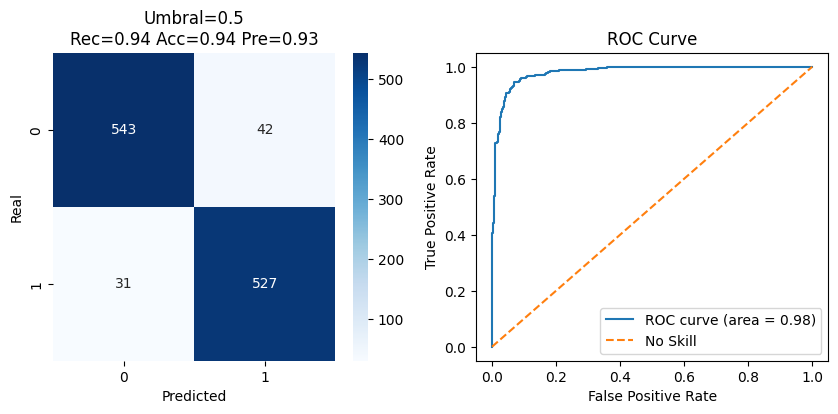

In [48]:
umbral=0.5

y_pred=y_pred_probs[:]>=umbral

fig, axes = plt.subplots(1,2)
fig.set_size_inches(10, 4)

matriz = confusion_matrix(y_test, y_pred)    
ax=axes[0]
sns.heatmap(matriz, annot=True, ax = ax, cmap="Blues",fmt="d");
ax.set_title("Umbral="+str(umbral)+"\nRec="+str(round(recall_score(y_test, y_pred),2))+
        " Acc="+str(round(accuracy_score(y_test, y_pred),2))+
        " Pre="+str(round(precision_score(y_test, y_pred),2)))
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Real')

fpt = 0
tpr = 0
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs) 
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
axes[1].plot([0, 1], [0, 1], '--', label='No Skill')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

In [54]:
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       585
           1       0.93      0.94      0.94       558

    accuracy                           0.94      1143
   macro avg       0.94      0.94      0.94      1143
weighted avg       0.94      0.94      0.94      1143



In [2]:
# Guardar el escalador ajustado
joblib.dump(scaler, "scaler.pkl")
print("Escalador guardado en scaler.pkl")

NameError: name 'scaler' is not defined

In [124]:
model.save("modelo_phishing.keras")
print("Modelo guardado como modelo_phishing.keras")

Modelo guardado como modelo_phishing.keras


In [3]:
import metodos_caracteristicas as mt

def extract_features_url(url):
    
    # Inicializar características
    features = {
        'google_index': 0,
        'nb_qm': 0,
        'nb_www': 0,
        'ratio_digits_host': 0.000000,
        'nb_hyperlinks': 0,
        'nb_hyphens': 0,
        'domain_in_title': 0,
        'nb_dots': 0,
        'nb_eq': 0,
        'length_hostname': 0,
        'domain_age': 0,
        'ratio_digits_url': 0,
        'domain_with_copyright': 0,
        'https_token': 0,
        'whois_registered_domain': 0,
        'tld_in_subdomain': 0,
        'dns_record': 0,
        'prefix_suffix': 0
    }

    features['google_index'] = mt.check_google_index(url)

    features['nb_qm'] = mt.count_nb_qm(url)

    features['nb_www'] = mt.count_nb_www(url)

    features['ratio_digits_host'] = mt.ratio_digits_host(url)

    features['nb_hyperlinks'] = mt.nb_hyperlinks(url)

    features['nb_hyphens'] = mt.count_nb_hyphens(url)

    features['domain_in_title'] = mt.domain_in_title(url)

    features['nb_dots'] = mt.count_nb_dots(url)

    features['nb_eq'] = mt.count_nb_eq(url)

    features['length_hostname'] = mt.count_length_hostname(url)

    features['domain_age'] = mt.get_domain_age(url)

    features['ratio_digits_url'] = mt.ratio_digits_url(url)

    features['domain_with_copyright'] = mt.domain_with_copyright(url)

    features['https_token'] = mt.https_token(url)

    features['whois_registered_domain'] = mt.whois_registered_domain(url)

    features['tld_in_subdomain'] = mt.tld_in_subdomain(url)

    features['dns_record'] = mt.dns_record(url)

    features['prefix_suffix'] = mt.prefix_suffix(url)

    return features

url = "http://www.crestonwood.com/router"
url = "https://www.lider.cl/supermercado/category/Precios_WOW/Supermercado?ads_name=2024-11-21_Sli1_precios_wow_ID:22011&ads_position=Slide_1&ads_id=GR&slot_id=WC54OWB3R9BY&slot_name=home-banner-1-desktop"
url = "https://escuelamartinpescador.cl/blog/2020/09/06/minuta-de-colaciones/"
url = "https://escuelamartinpescador.cl/reglamento/"
url = "https://support.paramountplus.com/s/contactsupport?language=es_MX"
url = "https://csirt.gob.cl/"
url = "https://www.chileautos.cl/vehiculos/detalles/audi-a3-2024-aut/GI-AD-698381/?Cr=1"
url = "https://simple.ripley.cl/moda-hombre/marcas-internacionales/lacoste?s=mdco"
url = "https://www.facebook.com/photo/?fbid=10157385558053903&set=ecnf.100069838495298&locale=es_LA"

features = extract_features_url(url)
for key, value in features.items():
    print(f"{key}: {value}")

google_index: 1
nb_qm: 1
nb_www: 1
ratio_digits_host: 0.0
nb_hyperlinks: 15
nb_hyphens: 0
domain_in_title: 1
nb_dots: 3
nb_eq: 3
length_hostname: 16
domain_age: 10108
ratio_digits_url: 0.347826
domain_with_copyright: 0
https_token: 1
whois_registered_domain: 1
tld_in_subdomain: 0
dns_record: 1
prefix_suffix: 0


In [40]:
import metodos_caracteristicas_mejorado3 as mt3

print(mt3.extract_features_url_analyze(url))


Tiempos de Ejecución:
google_index_execution: 0.4969 segundos
analyze_page_content_execution: 0.0000 segundos
analyze_domain_whois_execution: 0.4529 segundos
dns_record_execution: 0.0000 segundos
parallel_execution: 0.9558 segundos
count_nb_qm: 0.0000 segundos
count_nb_www: 0.0000 segundos
ratio_digits_host: 0.0000 segundos
count_nb_hyphens: 0.0000 segundos
count_nb_dots: 0.0000 segundos
count_nb_eq: 0.0000 segundos
count_length_hostname: 0.0000 segundos
ratio_digits_url: 0.0000 segundos
https_token: 0.0000 segundos
tld_in_subdomain: 0.0000 segundos
prefix_suffix: 0.0000 segundos
sequential_execution: 0.0000 segundos
{'google_index': 1, 'nb_qm': 1, 'nb_www': 1, 'ratio_digits_host': 0.0, 'nb_hyperlinks': 15, 'nb_hyphens': 0, 'domain_in_title': 1, 'nb_dots': 3, 'nb_eq': 3, 'length_hostname': 16, 'domain_age': 10108, 'ratio_digits_url': 0.347826, 'domain_with_copyright': 0, 'https_token': 1, 'whois_registered_domain': 1, 'tld_in_subdomain': 0, 'dns_record': 1, 'prefix_suffix': 0}


In [67]:
X_new

,google_index,nb_qm,nb_www,ratio_digits_host,nb_hyperlinks,nb_hyphens,domain_in_title,nb_dots,nb_eq,length_hostname,domain_age,ratio_digits_url,domain_with_copyright,https_token,whois_registered_domain,tld_in_subdomain,dns_record,prefix_suffix
0,0,0,1,0.000000,17,0,1,3,0,19,-1,0.000000,0,0,1,0,0,0
1,0,0,0,0.000000,30,0,0,1,0,23,5767,0.220779,1,0,1,0,1,0
2,0,1,0,0.000000,4,1,0,4,3,50,4004,0.150794,1,1,1,1,1,1
3,1,0,0,0.000000,149,0,0,2,0,11,-1,0.000000,1,0,1,0,1,0
4,1,0,1,0.000000,102,2,1,2,0,15,8175,0.000000,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,1,0,1,0.000000,199,0,1,2,0,17,5396,0.000000,1,0,1,0,1,0
11426,0,1,1,0.000000,3,0,0,5,1,18,6728,0.023810,1,0,1,0,1,0
11427,0,1,1,0.000000,68,6,1,2,1,16,8515,0.142857,1,1,1,0,1,0
11428,1,0,1,0.000000,32,0,0,2,0,30,2836,0.000000,1,0,1,0,1,0


In [5]:
#Cargar modelo pre-entrenado
model_cargado = load_model("modelo_phishing.keras")

scaler_cargado = joblib.load("scaler.pkl")

In [6]:
def predecir_probabilidad_phishing_url(url, nombres_columnas):

    # Extraer las características de la URL
    caracteristicas = extract_features_url(url)
    
    # Convertir las características a un DataFrame de pandas con los nombres de columna
    caracteristicas_df = pd.DataFrame([caracteristicas], columns=nombres_columnas)
    
    # Escalar las características
    caracteristicas_escaladas = scaler_cargado.transform(caracteristicas_df)

    # Realizar la predicción
    probabilidad = model_cargado.predict(caracteristicas_escaladas)[0][0]  # Probabilidad de clase positiva (phishing)

    return probabilidad

# Ejemplo de uso
nombres_columnas = [
    'google_index', 'nb_qm', 'nb_www', 'ratio_digits_host', 'nb_hyperlinks',
    'nb_hyphens', 'domain_in_title', 'nb_dots', 'nb_eq', 'length_hostname',
    'domain_age', 'ratio_digits_url', 'domain_with_copyright', 'https_token',
    'whois_registered_domain', 'tld_in_subdomain', 'dns_record', 'prefix_suffix'
]

url_ejemplo = "https://www.chileautos.cl/vehiculos/detalles/audi-a3-2024-aut/GI-AD-698381/?Cr=1"

# Calcular la probabilidad de phishing para una URL
probabilidad_phishing = predecir_probabilidad_phishing_url(url_ejemplo, nombres_columnas)
print(f"Probabilidad de phishing: {probabilidad_phishing}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step
Probabilidad de phishing: 0.12981151044368744


In [79]:
X_new

,google_index,nb_qm,nb_www,ratio_digits_host,nb_hyperlinks,nb_hyphens,domain_in_title,nb_dots,nb_eq,length_hostname,domain_age,ratio_digits_url,domain_with_copyright,https_token,whois_registered_domain,tld_in_subdomain,dns_record,prefix_suffix
0,0,0,1,0.000000,17,0,1,3,0,19,-1,0.000000,0,0,1,0,0,0
1,0,0,0,0.000000,30,0,0,1,0,23,5767,0.220779,1,0,1,0,1,0
2,0,1,0,0.000000,4,1,0,4,3,50,4004,0.150794,1,1,1,1,1,1
3,1,0,0,0.000000,149,0,0,2,0,11,-1,0.000000,1,0,1,0,1,0
4,1,0,1,0.000000,102,2,1,2,0,15,8175,0.000000,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,1,0,1,0.000000,199,0,1,2,0,17,5396,0.000000,1,0,1,0,1,0
11426,0,1,1,0.000000,3,0,0,5,1,18,6728,0.023810,1,0,1,0,1,0
11427,0,1,1,0.000000,68,6,1,2,1,16,8515,0.142857,1,1,1,0,1,0
11428,1,0,1,0.000000,32,0,0,2,0,30,2836,0.000000,1,0,1,0,1,0


In [32]:
def predecir_probabilidad_phishing_manual(caracteristicas, nombres_columnas):

    # Convertir las características a un DataFrame de pandas con los nombres de columna
    caracteristicas_df = pd.DataFrame([caracteristicas], columns=nombres_columnas)
    
    # Escalar las características
    caracteristicas_escaladas = scaler_cargado.transform(caracteristicas_df)

    # Realizar la predicción
    probabilidad = model_cargado.predict(caracteristicas_escaladas)[0][0]  # Probabilidad de clase positiva (phishing)

    return probabilidad

# Nombres de las características seleccionadas
nombres_columnas = [
    'google_index', 'nb_qm', 'nb_www', 'ratio_digits_host', 'nb_hyperlinks',
    'nb_hyphens', 'domain_in_title', 'nb_dots', 'nb_eq', 'length_hostname',
    'domain_age', 'ratio_digits_url', 'domain_with_copyright', 'https_token',
    'whois_registered_domain', 'tld_in_subdomain', 'dns_record', 'prefix_suffix'
]

# Características manualmente ingresadas (valores hipotéticos)
# Características de ejemplo extraídas de la imagen
caracteristicas_ejemplo = [
    1,  # google_index
    1,  # nb_qm
    0,  # nb_www
    0.000000,  # ratio_digits_host
    0,  # nb_hyperlinks
    2,  # nb_hyphens
    0,  # domain_in_title
    2,  # nb_dots
    1,  # nb_eq
    16,  # length_hostname
    9991,  # domain_age
    0.000000,  # ratio_digits_url
    0,  # domain_with_copyright
    1,  # https_token
    1,  # whois_registered_domain
    0,  # tld_in_subdomain
    1,  # dns_record
    1   # prefix_suffix
]

# Calcular la probabilidad de phishing manual
probabilidad_phishing = predecir_probabilidad_phishing_manual(caracteristicas_ejemplo, nombres_columnas)
print(f"Probabilidad de phishing: {probabilidad_phishing:.2%}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Probabilidad de phishing: 80.27%


In [118]:
# Combinar las columnas seleccionadas
subset = pd.concat([data["url"], X_new, data["status"]], axis=1)

In [119]:
subset

,url,google_index,nb_qm,nb_www,ratio_digits_host,nb_hyperlinks,nb_hyphens,domain_in_title,nb_dots,nb_eq,length_hostname,domain_age,ratio_digits_url,domain_with_copyright,https_token,whois_registered_domain,tld_in_subdomain,dns_record,prefix_suffix,status
0,http://www.crestonwood.com/router.php,0,0,1,0.000000,17,0,1,3,0,19,-1,0.000000,0,0,1,0,0,0,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,0,0,0,0.000000,30,0,0,1,0,23,5767,0.220779,1,0,1,0,1,0,phishing
2,https://support-appleld.com.secureupdate.duila...,0,1,0,0.000000,4,1,0,4,3,50,4004,0.150794,1,1,1,1,1,1,phishing
3,http://rgipt.ac.in,1,0,0,0.000000,149,0,0,2,0,11,-1,0.000000,1,0,1,0,1,0,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,1,0,1,0.000000,102,2,1,2,0,15,8175,0.000000,0,0,1,0,1,0,legitimate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11425,http://www.fontspace.com/category/blackletter,1,0,1,0.000000,199,0,1,2,0,17,5396,0.000000,1,0,1,0,1,0,legitimate
11426,http://www.budgetbots.com/server.php/Server%20...,0,1,1,0.000000,3,0,0,5,1,18,6728,0.023810,1,0,1,0,1,0,phishing
11427,https://www.facebook.com/Interactive-Televisio...,0,1,1,0.000000,68,6,1,2,1,16,8515,0.142857,1,1,1,0,1,0,legitimate
11428,http://www.mypublicdomainpictures.com/,1,0,1,0.000000,32,0,0,2,0,30,2836,0.000000,1,0,1,0,1,0,legitimate


In [120]:
subset.drop(columns=["url"]).to_csv("dataset_entrada.csv", index=False)

In [123]:
def predecir_dataset(model, scaler, input_csv, output_csv):

    # Cargar el dataset
    data = pd.read_csv(input_csv)

    # Separar características (asegúrate de que las columnas coincidan con las esperadas)
    X = data.iloc[:, :-1]  # Todas las columnas excepto la última (status)
    y = data.iloc[:, -1]   # La última columna es `status`

    # Escalar las características
    X_scaled = scaler.transform(X)

    # Realizar las predicciones
    y_pred_probs = model.predict(X_scaled)  # Predicciones en probabilidades
    y_pred = (y_pred_probs > 0.5).astype(int)  # Convertir a clases binarias (0 o 1)

    # Agregar la predicción como una nueva columna
    data['Predicción'] = y_pred
    data['Probabilidad'] = y_pred_probs.flatten()

    # Guardar el archivo de salida
    data.to_csv(output_csv, index=False)

    print(f"Archivo de salida guardado en: {output_csv}")

# Ejemplo de uso:
# Define las rutas de entrada y salida
input_csv = 'dataset_entrada.csv'  # Reemplaza con tu archivo CSV de entrada
output_csv = 'dataset_salida.csv'  # Archivo de salida con las predicciones

# Llamar al método para predecir
predecir_dataset(model, scaler, input_csv, output_csv)


358/358 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step
Archivo de salida guardado en: dataset_salida.csv


In [ ]:
########################################################################################################################################################################################################################################################################################################################################################################################################################################################################################################################
########################################################################################################################################################################################################################################################################################################################################################################
####################################################################################################################################################################################################################################################################################################################################
########################################################################################################################################################################################################################################################################################################################################################################

In [ ]:
import csv
# Leer las URLs desde el archivo CSV
archivo_csv = "urls_extraidas_phishing.csv"
urls = []

with open(archivo_csv, 'r', encoding='utf-8') as file:
    reader = csv.reader(file)
    for row in reader:
        if row:  # Asegurarse de que no haya filas vacías
            urls.append(row[0])

# Procesar cada URL y calcular su probabilidad de phishing
resultados = []

for url in urls:
    try:
        # Calcular la probabilidad de phishing para la URL
        probabilidad = predecir_probabilidad_phishing_url(model, scaler, url, nombres_columnas)
        resultados.append((url, probabilidad))
    except Exception as e:
        print(f"Error procesando URL: {url} - {e}")
        resultados.append((url, None))  # Si hay error, marcar como None

# Guardar los resultados en un nuevo archivo CSV
archivo_resultados = "urls_extraidas_resultados.csv"

with open(archivo_resultados, 'w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerow(["URL", "Probabilidad de Phishing"])  # Escribir encabezado
    for url, probabilidad in resultados:
        writer.writerow([url, probabilidad if probabilidad is not None else "Error"])

print(f"Resultados guardados en '{archivo_resultados}'.")